# Border Region: Mandatory Breaks vs Unconstrained

Compares charging demand allocation in the DE-AT-IT border region
between unconstrained (UNC) and mandatory breaks (BRK) runs,
across all 4 GENeSYS-MOD scenarios.

In [1]:
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
import re, warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': 'mathpazo',
    'font.size': 20,
    'axes.labelsize': 20
})

BASE_PATH = Path.cwd()
INPUT_DIR = BASE_PATH / 'input_data'
RESULTS_DIR = BASE_PATH / 'results'
FIG_DIR = BASE_PATH / 'figures'
FIG_DIR.mkdir(exist_ok=True)
print(f'Base path: {BASE_PATH}')

Base path: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM


In [8]:
# ============================================================
# Configuration — matching visualize_4_scenarios.ipynb
# ============================================================
SCENARIOS = {
    'scenario_000': {'name': 'Go RES',         'color': '#335c67'},
    'scenario_001': {'name': 'NECPEssentials',  'color': '#e09f3e'},
    'scenario_002': {'name': 'REPowerEU++',     'color': '#457b9d'},
    'scenario_003': {'name': 'Trinity',         'color': '#9e2a2b'},
}

UNC_DIR = RESULTS_DIR / 'uncertainty_scenarios'        # without breaks
BRK_DIR = RESULTS_DIR / 'uncertainty_scenarios_breaks_only'  # with breaks

SOUTHERN_BORDER_REGIONS = {
    'AT33', 'AT34',
    'ITC4', 'ITH1', 'ITH2', 'ITH3',
    'DE14', 'DE21', 'DE27',
}

BORDER_COUNTRY_MAP = {}
for r in SOUTHERN_BORDER_REGIONS:
    BORDER_COUNTRY_MAP[r] = r[:2]

COUNTRY_COLORS = {'AT': '#E63946', 'IT': '#457B9D', 'DE': '#2A9D8F'}
COUNTRY_ORDER = ['AT', 'IT', 'DE']

Y_INIT = 2020
TIME_STEP = 4
TARGET_YEAR = 2032

print(f'Scenarios: {[c["name"] for c in SCENARIOS.values()]}')
print(f'Target year: {TARGET_YEAR}')

Scenarios: ['Go RES', 'NECPEssentials', 'REPowerEU++', 'Trinity']
Target year: 2032


In [9]:
# ============================================================
# Loading utilities
# ============================================================

def load_yaml_file(filepath):
    with open(filepath, 'r', encoding='utf-8') as f:
        return yaml.safe_load(f)

def load_yaml_unsafe(filepath):
    with open(filepath, 'r', encoding='utf-8') as f:
        return yaml.load(f, Loader=yaml.UnsafeLoader)

def find_latest_result_file(folder, variable):
    files = list(folder.glob(f'*_{variable}_dict.yaml'))
    return max(files, key=lambda x: x.stat().st_mtime) if files else None

def parse_tuple_key(key_str):
    nums = re.findall(r'-?\d+', str(key_str))
    return tuple(int(x) for x in nums)

def load_f_dict(filepath):
    raw = load_yaml_file(filepath)
    result = {}
    for k, v in raw.items():
        nums = parse_tuple_key(k)
        if len(nums) >= 7:
            key = (nums[0], (nums[1], nums[2], nums[3]), (nums[4], nums[5]), nums[6])
            result[key] = float(v)
    return result

# Load shared data (same across scenarios)
path_data = load_yaml_unsafe(INPUT_DIR / 'fixed_nuts_2' / 'Path.yaml')
path_by_id = {}
for p in path_data:
    path_by_id[p['id']] = {
        'sequence': [int(x) for x in p['sequence']],
        'distance_from_previous': [float(x) for x in p['distance_from_previous']],
    }
print(f'Paths: {len(path_by_id)}')

# Geo element -> NUTS2 mapping (use scenario_000)
geo_yaml = load_yaml_file(INPUT_DIR / 'uncertainty_scenarios' / 'scenario_000' / 'GeographicElement.yaml')
geo_by_id = {}
for g in geo_yaml:
    if g.get('type') == 'node':
        geo_by_id[g['id']] = {
            'nuts2': g.get('nuts2_region', ''),
            'country': g.get('country', ''),
        }

# TechVehicle specs
tv_yaml = load_yaml_file(INPUT_DIR / 'uncertainty_scenarios' / 'scenario_000' / 'TechVehicle.yaml')
spec_cons = {tv['id']: tv['spec_cons'] for tv in tv_yaml}
w_payload = {tv['id']: tv['W'] for tv in tv_yaml}

print(f'Geo elements: {len(geo_by_id)}, TechVehicles: {len(spec_cons)}')

Paths: 6055
Geo elements: 81, TechVehicles: 2


In [10]:
# ============================================================
# Compute border region electricity by country
# Uses f_dict to walk flows along path sequences
# ============================================================

def border_electricity_by_country(f_dict, target_year, tv_filter=1):
    """
    Compute BEV electricity in border NUTS-2 regions, grouped by country.
    Returns: {'AT': GWh, 'IT': GWh, 'DE': GWh}
    """
    by_country = defaultdict(float)  # country -> MWh
    
    for key, tonnes_kt in f_dict.items():
        year = key[0]
        if year != target_year:
            continue
        path_id = key[1][2]
        mode_id = key[2][0]
        tv_id = key[2][1]
        gen = key[3]
        
        if mode_id != 1 or tv_id != tv_filter or tonnes_kt <= 0:
            continue
        
        pi = path_by_id.get(path_id)
        if pi is None:
            continue
        
        gen_idx = min(max(gen - Y_INIT, 0), len(spec_cons[tv_id]) - 1)
        sc = spec_cons[tv_id][gen_idx]
        w = w_payload[tv_id][gen_idx]
        
        for i, node_id in enumerate(pi['sequence']):
            seg_km = pi['distance_from_previous'][i]
            if seg_km <= 0:
                continue
            geo = geo_by_id.get(node_id)
            if geo is None:
                continue
            nuts2 = geo['nuts2']
            if nuts2 not in SOUTHERN_BORDER_REGIONS:
                continue
            country = BORDER_COUNTRY_MAP[nuts2]
            energy_mwh = (tonnes_kt * 1000 / w) * sc * seg_km / 1000
            by_country[country] += energy_mwh
    
    return {c: by_country.get(c, 0) / 1000 for c in COUNTRY_ORDER}  # GWh

# Load and compute for all scenarios x {UNC, BRK}
results = []

for scen_id, cfg in SCENARIOS.items():
    scen_name = cfg['name']
    
    for run_type, run_dir in [('UNC', UNC_DIR), ('BRK', BRK_DIR)]:
        f_file = find_latest_result_file(run_dir / scen_id, 'f')
        if f_file is None:
            print(f'  WARNING: No f_dict for {scen_name} {run_type}')
            continue
        print(f'Loading {scen_name} {run_type}: {f_file.name}')
        f_dict = load_f_dict(f_file)
        elec = border_electricity_by_country(f_dict, TARGET_YEAR)
        results.append({
            'scenario': scen_name,
            'scenario_id': scen_id,
            'run': run_type,
            'AT': elec['AT'],
            'IT': elec['IT'],
            'DE': elec['DE'],
            'Total': sum(elec.values()),
        })
        del f_dict

df = pd.DataFrame(results)
print(f'\nLoaded {len(df)} runs')
display(df)

Loading Go RES UNC: scenario_000_cs_2026-02-11_11-52-48_f_dict.yaml
Loading Go RES BRK: scenario_000_cs_2026-02-11_12-48-22_f_dict.yaml
Loading NECPEssentials UNC: scenario_001_cs_2026-02-11_12-14-54_f_dict.yaml
Loading NECPEssentials BRK: scenario_001_cs_2026-02-11_13-14-27_f_dict.yaml
Loading REPowerEU++ UNC: scenario_002_cs_2026-02-11_12-48-36_f_dict.yaml
Loading REPowerEU++ BRK: scenario_002_cs_2026-02-11_13-38-11_f_dict.yaml
Loading Trinity UNC: scenario_003_cs_2026-02-11_13-15-34_f_dict.yaml
Loading Trinity BRK: scenario_003_cs_2026-02-11_14-02-22_f_dict.yaml

Loaded 8 runs


,scenario,scenario_id,run,AT,IT,DE,Total
0,Go RES,scenario_000,UNC,12.796574,23.540869,41.698274,78.035717
1,Go RES,scenario_000,BRK,12.505475,24.557000,24.100578,61.163053
2,NECPEssentials,scenario_001,UNC,12.140244,24.208975,37.181153,73.530372
3,NECPEssentials,scenario_001,BRK,13.084396,24.517990,35.541527,73.143912
4,REPowerEU++,scenario_002,UNC,27.629558,51.628891,86.983834,166.242283
5,REPowerEU++,scenario_002,BRK,23.412149,40.391220,73.496164,137.299533
6,Trinity,scenario_003,UNC,13.372438,24.545445,41.824677,79.742559
7,Trinity,scenario_003,BRK,10.542439,17.203631,35.763005,63.509075


Saved: figures/border_breaks_comparison_2032.pdf


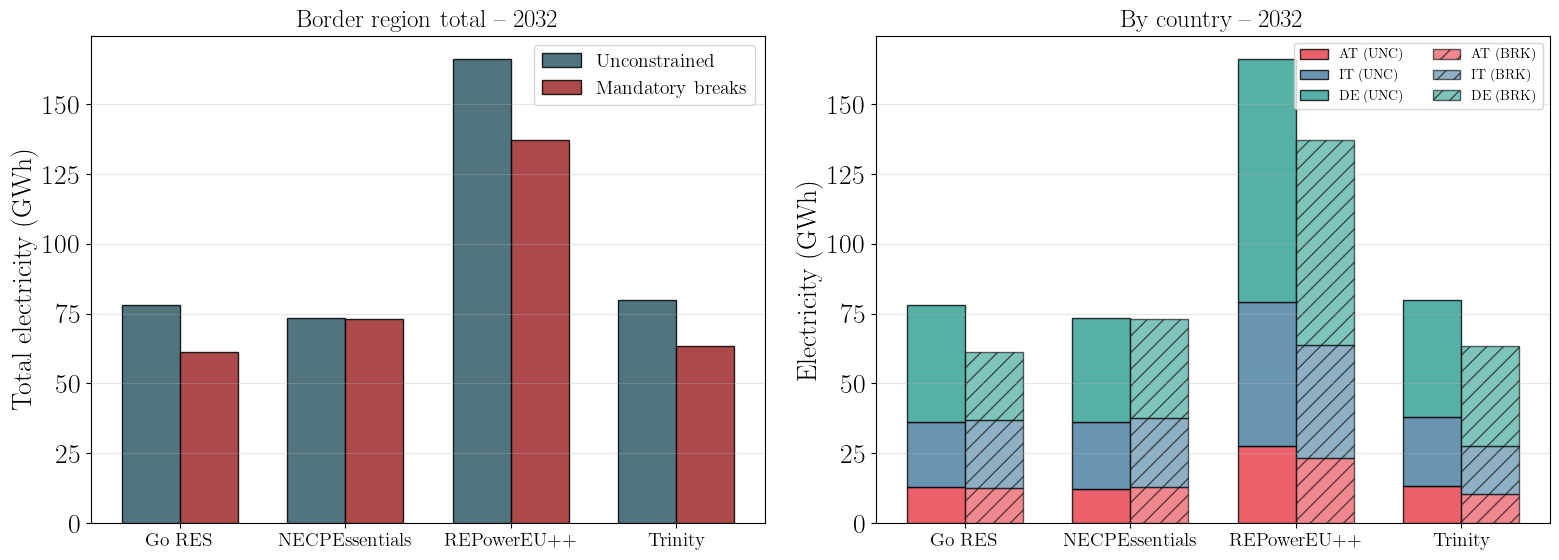

In [11]:
# ============================================================
# Figure: Border region electricity UNC vs BRK, by country
# Left: stacked bars by country for each scenario x run
# ============================================================

scen_names = [cfg['name'] for cfg in SCENARIOS.values()]
n_scen = len(scen_names)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Panel 1: Total electricity, UNC vs BRK ---
ax = axes[0]
x = np.arange(n_scen)
width = 0.35

unc_totals = [df[(df['scenario'] == s) & (df['run'] == 'UNC')]['Total'].values[0]
              for s in scen_names]
brk_totals = [df[(df['scenario'] == s) & (df['run'] == 'BRK')]['Total'].values[0]
              for s in scen_names]

bars_unc = ax.bar(x - width/2, unc_totals, width, label='Unconstrained',
                   color='#335c67', alpha=0.85, edgecolor='black')
bars_brk = ax.bar(x + width/2, brk_totals, width, label='Mandatory breaks',
                   color='#9e2a2b', alpha=0.85, edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(scen_names, fontsize=14)
ax.set_ylabel('Total electricity (GWh)')
ax.set_title(f'Border region total -- {TARGET_YEAR}', fontsize=18)
ax.legend(fontsize=14)
ax.grid(True, alpha=0.3, axis='y')

# --- Panel 2: Stacked by country, UNC vs BRK side by side ---
ax = axes[1]
x = np.arange(n_scen)

for run_idx, (run_type, offset) in enumerate([('UNC', -width/2), ('BRK', width/2)]):
    bottom = np.zeros(n_scen)
    for country in COUNTRY_ORDER:
        vals = np.array([df[(df['scenario'] == s) & (df['run'] == run_type)][country].values[0]
                         for s in scen_names])
        hatch = '' if run_type == 'UNC' else '//'
        label = f'{country} ({run_type})'
        ax.bar(x + offset, vals, width, bottom=bottom,
               color=COUNTRY_COLORS[country], alpha=0.8 if run_type == 'UNC' else 0.6,
               edgecolor='black', hatch=hatch, label=label)
        bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(scen_names, fontsize=14)
ax.set_ylabel('Electricity (GWh)')
ax.set_title(f'By country -- {TARGET_YEAR}', fontsize=18)
ax.legend(fontsize=10, ncol=2, loc='upper right')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
fname = f'border_breaks_comparison_{TARGET_YEAR}'
plt.savefig(FIG_DIR / f'{fname}.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / f'{fname}.svg', bbox_inches='tight')
print(f'Saved: figures/{fname}.pdf')
plt.show()

In [12]:
# ============================================================
# Delta table: BRK vs UNC
# ============================================================
print(f'Border region electricity delta (BRK - UNC), {TARGET_YEAR}')
print('=' * 80)
print(f'{"Scenario":<18} {"UNC (GWh)":>10} {"BRK (GWh)":>10} {"Delta":>10} {"Delta %":>10}')
print(f'{"-"*18} {"-"*10} {"-"*10} {"-"*10} {"-"*10}')

for scen_name in scen_names:
    unc_row = df[(df['scenario'] == scen_name) & (df['run'] == 'UNC')].iloc[0]
    brk_row = df[(df['scenario'] == scen_name) & (df['run'] == 'BRK')].iloc[0]
    delta = brk_row['Total'] - unc_row['Total']
    pct = delta / unc_row['Total'] * 100 if unc_row['Total'] > 0 else 0
    print(f'{scen_name:<18} {unc_row["Total"]:>10.1f} {brk_row["Total"]:>10.1f} '
          f'{delta:>+10.1f} {pct:>+9.1f}%')
    
    # Per-country breakdown
    for c in COUNTRY_ORDER:
        d = brk_row[c] - unc_row[c]
        p = d / unc_row[c] * 100 if unc_row[c] > 0 else 0
        print(f'  {c:<16} {unc_row[c]:>10.1f} {brk_row[c]:>10.1f} {d:>+10.1f} {p:>+9.1f}%')

Border region electricity delta (BRK - UNC), 2032
Scenario            UNC (GWh)  BRK (GWh)      Delta    Delta %
------------------ ---------- ---------- ---------- ----------
Go RES                   78.0       61.2      -16.9     -21.6%
  AT                     12.8       12.5       -0.3      -2.3%
  IT                     23.5       24.6       +1.0      +4.3%
  DE                     41.7       24.1      -17.6     -42.2%
NECPEssentials           73.5       73.1       -0.4      -0.5%
  AT                     12.1       13.1       +0.9      +7.8%
  IT                     24.2       24.5       +0.3      +1.3%
  DE                     37.2       35.5       -1.6      -4.4%
REPowerEU++             166.2      137.3      -28.9     -17.4%
  AT                     27.6       23.4       -4.2     -15.3%
  IT                     51.6       40.4      -11.2     -21.8%
  DE                     87.0       73.5      -13.5     -15.5%
Trinity                  79.7       63.5      -16.2     -20.4%
  AT 

Computing time series for Go RES...
Saved: figures/border_breaks_timeseries_Go_RES.pdf


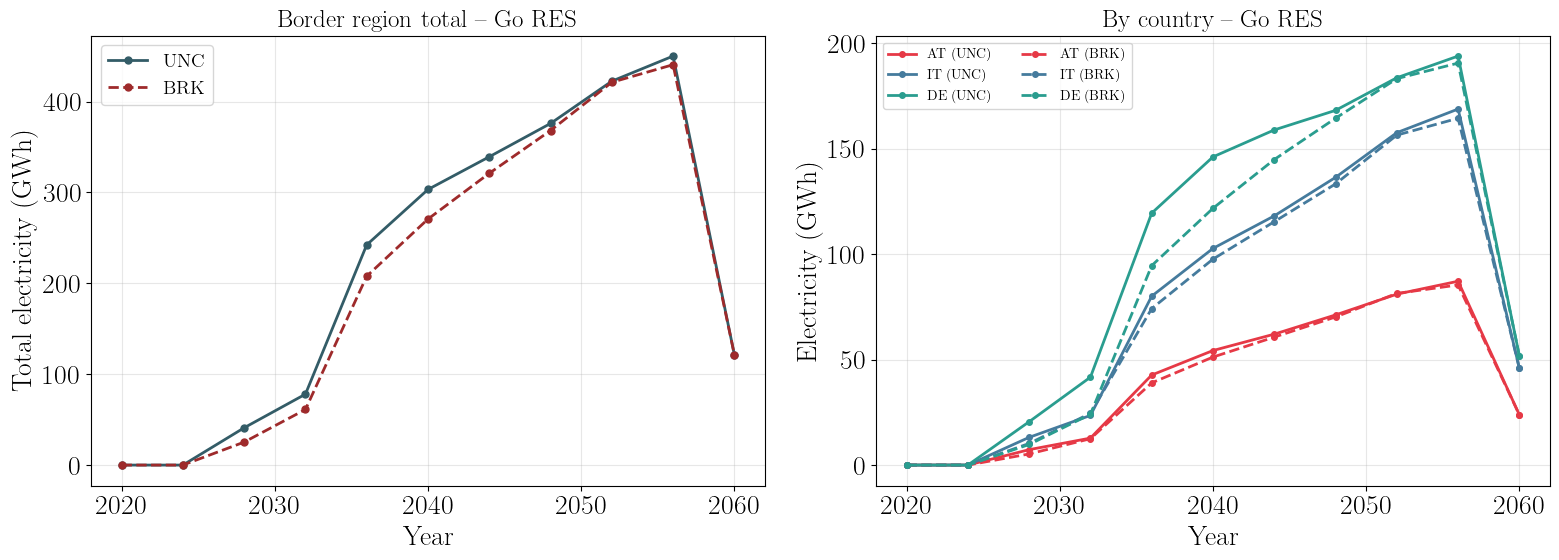

In [13]:
# ============================================================
# Time series: border electricity across all modeled years
# Focus on Go RES scenario
# ============================================================

FOCUS = 'scenario_000'
FOCUS_NAME = SCENARIOS[FOCUS]['name']
MODELED_YEARS = list(range(Y_INIT, 2061, TIME_STEP))

print(f'Computing time series for {FOCUS_NAME}...')

ts_results = []
for run_type, run_dir in [('UNC', UNC_DIR), ('BRK', BRK_DIR)]:
    f_file = find_latest_result_file(run_dir / FOCUS, 'f')
    if f_file is None:
        continue
    f_dict = load_f_dict(f_file)
    for year in MODELED_YEARS:
        elec = border_electricity_by_country(f_dict, year)
        ts_results.append({'year': year, 'run': run_type, **elec,
                           'Total': sum(elec.values())})
    del f_dict

df_ts = pd.DataFrame(ts_results)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Total over time
ax = axes[0]
for run_type, color, ls in [('UNC', '#335c67', '-'), ('BRK', '#9e2a2b', '--')]:
    sub = df_ts[df_ts['run'] == run_type]
    ax.plot(sub['year'], sub['Total'], color=color, linestyle=ls,
            marker='o', markersize=5, linewidth=2, label=run_type)
ax.set_xlabel('Year')
ax.set_ylabel('Total electricity (GWh)')
ax.set_title(f'Border region total -- {FOCUS_NAME}', fontsize=18)
ax.legend(fontsize=14)
ax.grid(True, alpha=0.3)

# Panel 2: By country, UNC solid, BRK dashed
ax = axes[1]
for run_type, ls in [('UNC', '-'), ('BRK', '--')]:
    sub = df_ts[df_ts['run'] == run_type]
    for country in COUNTRY_ORDER:
        label = f'{country} ({run_type})'
        ax.plot(sub['year'], sub[country], color=COUNTRY_COLORS[country],
                linestyle=ls, marker='o', markersize=4, linewidth=2, label=label)
ax.set_xlabel('Year')
ax.set_ylabel('Electricity (GWh)')
ax.set_title(f'By country -- {FOCUS_NAME}', fontsize=18)
ax.legend(fontsize=10, ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
fname = f'border_breaks_timeseries_{FOCUS_NAME.replace(" ", "_")}'
plt.savefig(FIG_DIR / f'{fname}.pdf', bbox_inches='tight')
print(f'Saved: figures/{fname}.pdf')
plt.show()